In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [2]:
X, y = make_classification(
    n_samples=10_000, n_features=10, n_informative=5,
    weights=[0.99], random_state=42
)
pd.Series(y).value_counts()

0    9853
1     147
Name: count, dtype: int64

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
y_pred_tonto = np.zeros_like(y_test)
accuracy_score(y_test, y_pred_tonto)

0.9853333333333333

              precision    recall  f1-score   support

           0      0.985     1.000     0.993      2956
           1      0.000     0.000     0.000        44

    accuracy                          0.985      3000
   macro avg      0.493     0.500     0.496      3000
weighted avg      0.971     0.985     0.978      3000



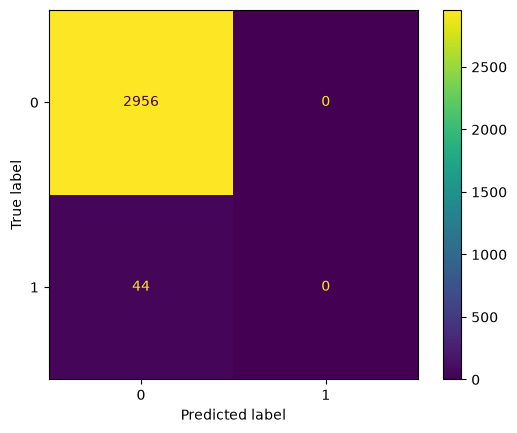

In [4]:
modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)
print(classification_report(y_test, y_pred, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred);

In [5]:
from sklearn.metrics import precision_score, recall_score, f1_score

resultados = []

def evaluar(nombre, y_true, y_pred):
    resultados.append({
        "técnica": nombre,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    })
    return pd.DataFrame(resultados).round(3)

evaluar("Modelo tonto", y_test, y_pred_tonto)
evaluar("Baseline (sin tratar)", y_test, y_pred)

,técnica,accuracy,precision,recall,f1
0,Modelo tonto,0.985,0.0,0.0,0.0
1,Baseline (sin tratar),0.985,0.0,0.0,0.0


,técnica,accuracy,precision,recall,f1
0,Modelo tonto,0.985,0.00,0.000,0.000
1,Baseline (sin tratar),0.985,0.00,0.000,0.000
2,class_weight='balanced',0.685,0.03,0.659,0.058


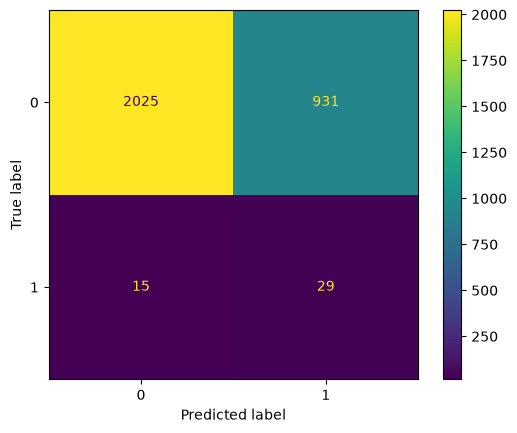

In [6]:
modelo_cw = LogisticRegression(max_iter=1000, class_weight="balanced")
modelo_cw.fit(X_train, y_train)
y_pred_cw = modelo_cw.predict(X_test)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_cw)
evaluar("class_weight='balanced'", y_test, y_pred_cw)

## Undersampling

In [7]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("Antes:", pd.Series(y_train).value_counts().to_dict())
print("Después:", pd.Series(y_train_rus).value_counts().to_dict())

modelo_rus = LogisticRegression(max_iter=1000)
modelo_rus.fit(X_train_rus, y_train_rus)
y_pred_rus = modelo_rus.predict(X_test)
evaluar("Undersampling", y_test, y_pred_rus)

Antes: {0: 6897, 1: 103}
Después: {0: 103, 1: 103}


,técnica,accuracy,precision,recall,f1
0,Modelo tonto,0.985,0.00,0.000,0.000
1,Baseline (sin tratar),0.985,0.00,0.000,0.000
2,class_weight='balanced',0.685,0.03,0.659,0.058
3,Undersampling,0.646,0.03,0.727,0.057


## SMOTE

In [8]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
print("Antes:", pd.Series(y_train).value_counts().to_dict())
print("Después:", pd.Series(y_train_sm).value_counts().to_dict())

modelo_sm = LogisticRegression(max_iter=1000)
modelo_sm.fit(X_train_sm, y_train_sm)
y_pred_sm = modelo_sm.predict(X_test)
evaluar("SMOTE", y_test, y_pred_sm)

Antes: {0: 6897, 1: 103}
Después: {0: 6897, 1: 6897}


,técnica,accuracy,precision,recall,f1
0,Modelo tonto,0.985,0.00,0.000,0.000
1,Baseline (sin tratar),0.985,0.00,0.000,0.000
2,class_weight='balanced',0.685,0.03,0.659,0.058
3,Undersampling,0.646,0.03,0.727,0.057
4,SMOTE,0.697,0.03,0.636,0.058
